<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/bonus/B11_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook B11 · Performance evaluation across horizons and datasets (bonus datasets)

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

This notebook scores every stored forecast of the 23 foundation models (Notebooks 05a to 09b) and the 16 baselines
(Notebook 10) with fourteen point-forecast metrics. It then builds results tables in the layout that published
forecasting comparisons commonly use (the best value in **bold**, the second best in *italic underlined*), and
compares the models across horizons, datasets and covariate settings.

#### Why more than one metric?

Each metric answers a different question: how big is the error, is it biased, does it beat the naive rule, can it
be compared across series? Each one can also be fooled. No single metric gives the full picture, and this notebook
shows with real numbers how much the choice of metric changes the ranking of the models.

The datasets are B1 and B2. Only point forecasts are evaluated here;
probabilistic evaluation (quantile loss, CRPS, coverage) is left to a later chapter.

**What you will learn**

- the definition, strengths and limitations of 14 point-forecast metrics, with the formula of each
- how to aggregate errors over windows, horizons and series without letting one scale dominate
- how to read a results table in the usual published layout, and why model rankings change with the metric

| Environment and compute | |
|---|---|
| Python | 3.12 or 3.13 |
| Packages | [`requirements-dataprep.txt`](../requirements-dataprep.txt) (the environment of Notebooks 00 to 04); no model library is needed |
| Hardware | CPU only; no GPU is needed |
| Network | none: reads the stored forecasts in `results/forecasts/` |
| Run time | about 2 minutes on 4 CPU cores (scoring is cached in `results/tables/scores_per_forecast.csv`) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs the few
  packages Colab lacks. If it says it is restarting the session, wait, then choose *Runtime > Run all* again.
- **Your own computer:** use the environment of Notebooks 00 to 04 (`requirements-dataprep.txt`) and run all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install the packages Colab lacks)
import os
import sys
from pathlib import Path

CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
DRIVE_COPY = ""   # Colab only, optional: path of your own copy of this folder on Google Drive
IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:
    import importlib.metadata as md
    import shutil

    BOOK = Path("/content/book")

    def chapter_dir():
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):   # copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    if chapter_dir() is None and not DRIVE_COPY:      # 1) clone the book's repository
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                         # 2) not on GitHub (yet): copy it from Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if not DRIVE_COPY or not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"{CHAPTER} is not on GitHub or in your Google Drive. Set DRIVE_COPY to its path.")
        shutil.rmtree(BOOK, ignore_errors=True)
        shutil.copytree(DRIVE_COPY, BOOK / CHAPTER,
                        ignore=lambda d, names: [n for n in names if n.startswith(".venv") or n == "__pycache__"])
    os.chdir(chapter_dir())
    loaded = {name: md.version(name) for name in ("numpy", "pandas", "scipy", "statsmodels")}
    # Install with uv, several times faster than pip. Colab comes with uv (installed here if not). The settings point
    # uv at Colab's own Python and drop install constraints left over from building Colab's image; pip is the fallback.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    !uv pip install -q -r requirements-colab.txt || {sys.executable} -m pip install -q -r requirements-colab.txt
    changed = [name for name, version in loaded.items() if md.version(name) != version]
    if changed:   # Colab had already imported the old version: restart once so Python loads the new one
        print(f"The install updated {', '.join(changed)}: restarting the session. Then choose Runtime > Run all again.")
        get_ipython().kernel.do_shutdown(True)
        raise SystemExit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS = ROOT / "data", ROOT / "results"
INPUT = ROOT / "input_timeseries"   # the frozen datasets (CSV) and the data dictionary
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}")

chapter folder: /home/user/v3  |  Python 3.12.3  |  Colab: False


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ch03_dataprep.plotting import set_style
from ch03_zeroshot.baselines import BASELINES
from ch03_zeroshot.capabilities import ZERO_SHOT_MODELS
from ch03_zeroshot.metrics import TABLE_METRICS, aggregate, catalogue_table
from ch03_zeroshot.data import load_frame
from ch03_zeroshot.report import (gain_tables, load_forecasts, model_colors, plot_horizons, scores_cached,
                                  series_list, show_forecast_tables, show_gains)
from ch03_zeroshot.tables import average_ranks, display_names, paper_table, save_table, style_table

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
DATASETS = ['B1', 'B2']
FMS = [r[0] for r in ZERO_SHOT_MODELS]
BASE = list(BASELINES)
NAMES = display_names()
TABLES = RESULTS / "tables" / "paper"

## 1 · Why one metric is not enough

An error metric compresses every error of a forecast, step by step and window by window, into one number. Each way of
compressing keeps some information and throws the rest away, and which information matters depends on the question
being asked. That is why forecasters report a small set of metrics, each answering a different question:

- **How large are the errors, in the units of the data?** MAE and RMSE read naturally (degrees Celsius, dollars per
  tonne, percentage points of yield), but they cannot be averaged across series measured in different units: an
  error on copper at about 13,000 dollars a tonne would swamp one on lead at about 2,000.
- **Are big misses rare or common?** RMSE squares the errors, so a few large misses weigh far more than many small
  ones; MAE weighs every unit of error the same. The two reward different forecasts (squared error is minimised by
  the mean of what may happen, absolute error by the median), so they can rank two models differently without
  either being wrong.
- **Does the model beat the obvious rule?** MASE and RMSSE divide a model's error by the in-sample error of the naive
  rule, MDRAE and FVA compare it with the naive forecast over the same window. These metrics are scale-free, so they
  can be averaged across series, datasets and horizons, and they say whether the model adds anything over a rule
  that needs no model at all.
- **Is the error large compared with the level of the series?** Percentage metrics (MAPE, sMAPE, MDAPE, MAAPE, WAPE)
  are familiar outside the field, but they need a true zero, blow up near it and are not symmetric. For
  temperatures in degrees Celsius they are meaningless: zero degrees is an arbitrary point of the scale, so a 1
  degree error on a 0.2 degree day becomes a 500% error. Theil's U1 also scales the error by the level.
- **Does the model err in one direction?** Every absolute or squared metric is blind to the sign of the error. The
  mean error and the tracking signal show the bias that MAE and RMSE hide.
- **Is the result driven by a few cases?** Means follow outliers; medians (MDAPE, MDRAE) describe the typical step
  and ignore a few explosive terms.

No metric answers all of these at once, and each one can be fooled: a forecast can have a low MAE and a strong bias,
a good MASE only because the naive rule is weak, or a tiny MAPE only because the series sits far from zero. The
practical rule is to report a small, complementary set (one metric in the units of the data, one scale-free metric,
one comparison with a benchmark and one bias measure) and to check whether the ranking of the models survives a
change of metric. The section *No single metric gives the full picture* below runs that check on our forecasts, and
Notebook 12 extends it to every consistent scoring rule with Murphy diagrams.

### The fourteen metrics

In the formulas, $y_t$ is the actual value at step $t$ of the forecast window, $\hat y_t$ the forecast, $H$ the horizon, $T$ the
number of training rows before the forecast origin, $\ell$ the naive lag (365 for daily temperature, 1 for prices,
oil and yields) and $\hat y^R_t$ the naive forecast over the same window.

#### In the units of the data

The **MAE** (mean absolute error) is the average size of the error, in the units of the series:

$$
\mathrm{MAE} = \frac{1}{H}\sum_{t=1}^{H}|y_t-\hat y_t|
$$

It is easy to read and robust to a few large errors, and it is minimised by the median of the forecast distribution. It cannot be averaged across series measured in different units.

The **RMSE** (root mean squared error) is the typical error, with large misses weighted more. It is the square root of the mean squared error (MSE):

$$
\mathrm{RMSE} = \sqrt{\mathrm{MSE}},\qquad \mathrm{MSE} = \frac{1}{H}\sum_{t=1}^{H}(y_t-\hat y_t)^2
$$

It penalises big misses and keeps the units of the data, but a few large errors can dominate it, and it too depends on the scale of the series.

The **mean error** (ME) shows systematic over-forecasting (ME < 0) or under-forecasting (ME > 0):

$$
\mathrm{ME} = \frac{1}{H}\sum_{t=1}^{H}(y_t-\hat y_t)
$$

It shows the direction of the errors, which no absolute metric does. Positive and negative errors cancel, though, so an ME of 0 does not mean that the forecast is accurate.

The **tracking signal** (TS) measures persistent bias relative to the size of the errors: the cumulative forecast error (CFE) divided by the mean absolute deviation (MAD),

$$
\mathrm{TS} = \frac{\mathrm{CFE}}{\mathrm{MAD}},\quad\mathrm{CFE}=\sum_{t=1}^{H}(y_t-\hat y_t),\quad\mathrm{MAD}=\frac{1}{H}\sum_{t=1}^{H}|y_t-\hat y_t|
$$

A value outside about [−4, 4] flags a biased model. The tracking signal was built for monitoring a running forecast and grows with the horizon (TS = H · ME/MAE), so this chapter compares the bias ratio ME/MAE, which lies between −1 and 1, instead.

#### Relative to the level of the series (percentages and Theil's U1)

The **MAPE** (mean absolute percentage error) is the average error as a percentage of the actual value:

$$
\mathrm{MAPE} = \frac{100}{H}\sum_{t=1}^{H}\left|\frac{y_t-\hat y_t}{y_t}\right|
$$

It is familiar to non-specialists, but it explodes near zero, is undefined at zero and is meaningless for interval scales such as degrees Celsius. It also penalises over-forecasts more than under-forecasts.

The **WAPE** (weighted absolute percentage error) is the total absolute error relative to the total level of the series:

$$
\mathrm{WAPE} = 100\thinspace\frac{\sum_t|y_t-\hat y_t|}{\sum_t|y_t|}
$$

It is stable and weights each step by its size, so a single zero does not blow it up, but it still needs a meaningful zero, and large levels dominate it.

The **sMAPE** (symmetric MAPE) compares each error with the average of the actual value and the forecast:

$$
\mathrm{sMAPE} = \frac{100}{H}\sum_{t=1}^{H}\frac{|y_t-\hat y_t|}{(|y_t|+|\hat y_t|)/2}
$$

It is bounded at 200% and was one of the two accuracy metrics of the M4 competition. Despite its name it is not symmetric: it punishes under-forecasts more, and it is unstable near zero.

The **MAAPE** (mean arctangent absolute percentage error) squashes each percentage error into the range from 0 to π/2 with the arctangent:

$$
\mathrm{MAAPE} = \frac{1}{H}\sum_{t=1}^{H}\arctan\left|\frac{y_t-\hat y_t}{y_t}\right|
$$

Being bounded, it cannot be dominated by a near-zero actual value, but its unit, the radian, is not intuitive, and it is rarely reported.

The **MDAPE** (median absolute percentage error) is the typical percentage error:

$$
\mathrm{MDAPE} = 100\cdot\mathrm{median}_ t\left|\frac{y_t-\hat y_t}{y_t}\right|
$$

The median ignores a few explosive terms, but the metric is still undefined at zero and misleading near it.

**Theil's U1** is the RMSE divided by the size of the actual values and of the forecasts:

$$
U_1 = \frac{\sqrt{\frac1H\sum_t(y_t-\hat y_t)^2}}{\sqrt{\frac1H\sum_t y_t^2}+\sqrt{\frac1H\sum_t\hat y_t^2}}
$$

It lies between 0 and 1, with 0 for a perfect forecast, but it depends on the level of the series: a series far from zero always scores close to 0.

#### Relative to the naive rule

The **MASE** (mean absolute scaled error) is the MAE divided by the in-sample error of the naive rule with lag $\ell$:

$$
\mathrm{MASE} = \frac{\frac1H\sum_t|y_t-\hat y_t|}{\frac{1}{T-\ell}\sum_{t=\ell+1}^{T}|y_t-y_{t-\ell}|}
$$

It is scale-free and defined for any series, and a value below 1 means smaller errors than the naive rule made in sample. It depends on that benchmark, though: a weak naive rule makes every model look good.

The **RMSSE** (root mean squared scaled error) divides the MSE by the in-sample mean squared error of the naive rule with lag $\ell$, and takes the square root:

$$
\mathrm{RMSSE} = \sqrt{\mathrm{MSE}/\mathrm{MSE}_ {\text{naive}}},\qquad \mathrm{MSE}_ {\text{naive}} = \frac{1}{T-\ell}\sum_{t=\ell+1}^{T}(y_t-y_{t-\ell})^2
$$

It is scale-free and based on squared errors (a weighted version was the accuracy metric of the M5 competition), and like the MASE it depends on the choice of naive rule.

The **MDRAE** (median relative absolute error) is the typical error relative to the naive forecast $\hat y^R_t$ over the same window:

$$
\mathrm{MDRAE} = \mathrm{median}_ t\frac{|y_t-\hat y_t|}{|y_t-\hat y^{R}_ t|}
$$

It is scale-free, and a value below 1 beats the naive forecast. A step where the naive forecast is exactly right would give an infinite ratio, so such steps are skipped.

The **forecast value added** (FVA) says how much a model improves on the naive forecast:

$$
\mathrm{FVA} = 100\thinspace(1-\mathrm{MAE}/\mathrm{MAE}_ {\text{naive}})
$$

It reads directly as a business statement, such as "12% better than naive", but it is only as meaningful as the benchmark.

#### What this chapter reports

The MASE is the headline, because it is scale-free and compares every model with the same naive rule. The RMSE sits
next to it in the units of the data, and the mean error shows bias. The results tables of Section 3 also carry the
sMAPE, Theil's U1, the MDRAE and the MDAPE, which together with the RMSE and the MASE make a six-metric set often
used in published forecasting comparisons, plus the MAE. Read their percentage columns with the caveats above, and
not at all for temperature. The section *No single metric gives the full picture* shows how far the metrics agree on
our data.

The code of the metrics (one function scores one forecast; `aggregate` averages over windows), from
[`src/ch03_zeroshot/metrics.py`](../src/ch03_zeroshot/metrics.py):

In [3]:
import numpy as np
import pandas as pd

# Naive benchmark and MASE/RMSSE scaling lag per dataset. Daily temperature: seasonal naive (same
# day last year), as in Notebook 03. Metal prices, oil and yields: last value (random walk), because
# Notebook 03 found no usable seasonal cycle in them (seasonal naive = naive there).
SCALE_LAG = {"D1": 365, "D2": 365, "D3": 1, "D4": 1, "B1": 1, "B2": 1}

# name: (label, formula, what it measures, strength, limitation, where it is defined)
CATALOGUE = {
    "MAE": ("MAE", r"\frac{1}{H}\sum_{t=1}^{H}|y_t-\hat y_t|",
            "average size of the error, in the units of the series",
            "easy to read; robust to a few large errors; minimised by the median",
            "scale-dependent: cannot be averaged across series of different units", "MMTSF 3.1"),
    "RMSE": ("RMSE", r"\sqrt{\mathrm{MSE}},\qquad \mathrm{MSE} = \frac{1}{H}\sum_{t=1}^{H}(y_t-\hat y_t)^2",
             "typical error with large misses weighted more", "penalises big misses; same units as the data",
             "dominated by a few large errors; scale-dependent", "MMTSF 3.1; Sengupta et al. (2025) Sec. 5.2"),
    "ME": ("ME (bias)", r"\frac{1}{H}\sum_{t=1}^{H}(y_t-\hat y_t)",
           "systematic over- (ME < 0) or under-forecasting (ME > 0)", "shows direction, which no absolute metric does",
           "positive and negative errors cancel: ME = 0 does not mean accurate", "MMTSF 3.1.1"),
    "TS": ("Tracking signal", r"\frac{\mathrm{CFE}}{\mathrm{MAD}},\quad\mathrm{CFE}=\sum_{t=1}^{H}(y_t-\hat y_t),\quad"
                              r"\mathrm{MAD}=\frac{1}{H}\sum_{t=1}^{H}|y_t-\hat y_t|",
           "persistent bias relative to the error size", "a value outside about [-4, 4] flags a biased model",
           "built for monitoring a running forecast; it grows with the horizon (TS = H · ME/MAE), so this chapter "
           "compares the bias ratio ME/MAE (between -1 and 1) instead", "MMTSF 3.1.1.2"),
    "MAPE": ("MAPE (%)", r"\frac{100}{H}\sum_{t=1}^{H}\left|\frac{y_t-\hat y_t}{y_t}\right|",
             "average error as a percentage of the actual value", "familiar to non-specialists",
             "explodes near zero, undefined at zero, meaningless for interval scales such as degrees Celsius; "
             "penalises over-forecasts more", "MMTSF 3.1.2"),
    "WAPE": ("WAPE (%)", r"100\,\frac{\sum_t|y_t-\hat y_t|}{\sum_t|y_t|}",
             "total absolute error relative to the total level", "stable, volume-weighted, no blow-up at single zeros",
             "still needs a meaningful zero; large levels dominate", "MMTSF 3.1.2.1"),
    "sMAPE": ("sMAPE (%)", r"\frac{100}{H}\sum_{t=1}^{H}\frac{|y_t-\hat y_t|}{(|y_t|+|\hat y_t|)/2}",
              "percentage error against the average of actual and forecast", "bounded at 200%; M4 standard",
              "not symmetric after all: punishes under-forecasts more; unstable near zero", "MMTSF 3.1.2.2"),
    "MAAPE": ("MAAPE (rad)", r"\frac{1}{H}\sum_{t=1}^{H}\arctan\left|\frac{y_t-\hat y_t}{y_t}\right|",
              "percentage error squashed into [0, π/2]", "bounded, so a near-zero actual cannot dominate",
              "units (radians) are not intuitive; rarely reported", "MMTSF 3.1.2.3"),
    "MDAPE": ("MDAPE (%)", r"100\cdot\mathrm{median}_t\left|\frac{y_t-\hat y_t}{y_t}\right|",
              "typical percentage error", "the median ignores a few explosive terms",
              "still undefined at zero and misleading near zero", "Sengupta et al. (2025) Sec. 5.2"),
    "MASE": ("MASE", r"\frac{\frac1H\sum_t|y_t-\hat y_t|}{\frac{1}{T-\ell}\sum_{t=\ell+1}^{T}|y_t-y_{t-\ell}|}",
             "MAE relative to the in-sample error of the naive rule (lag ℓ)", "scale-free, defined for any series; "
             "< 1 means smaller errors than the naive rule made in sample",
             "depends on the naive benchmark: a weak naive makes every model look good",
             "MMTSF 3.1.3; Hyndman and Koehler (2006)"),
    "RMSSE": ("RMSSE", r"\sqrt{\mathrm{MSE}/\mathrm{MSE}_{\text{naive}}},\qquad "
                      r"\mathrm{MSE}_{\text{naive}} = \frac{1}{T-\ell}\sum_{t=\ell+1}^{T}(y_t-y_{t-\ell})^2",
              "RMSE relative to the in-sample naive error", "scale-free and squared-error based (M5 metric)",
              "as MASE, sensitive to the choice of naive", "MMTSF 3.1.3"),
    "TU1": ("Theil's U1", r"\frac{\sqrt{\frac1H\sum_t(y_t-\hat y_t)^2}}{\sqrt{\frac1H\sum_t y_t^2}+\sqrt{\frac1H\sum_t\hat y_t^2}}",
            "RMSE normalised by the size of actuals and forecasts", "bounded in [0, 1]; 0 is a perfect forecast",
            "depends on the level of the series: series far from zero always score close to 0",
            "Theil (1966); Sengupta et al. (2025) Sec. 5.2"),
    "MDRAE": ("MDRAE", r"\mathrm{median}_t\frac{|y_t-\hat y_t|}{|y_t-\hat y^{R}_t|}",
              "typical error relative to the naive forecast over the same window", "scale-free; < 1 beats naive",
              "a step where naive is exactly right gives an infinite ratio (such steps are skipped)",
              "Sengupta et al. (2025) Sec. 5.2"),
    "FVA": ("FVA (%)", r"100\,(1-\mathrm{MAE}/\mathrm{MAE}_{\text{naive}})",
            "how much a model improves on the naive forecast", "direct business reading: +12% better than naive",
            "only as meaningful as the benchmark", "MMTSF 3.2; Gilliland (2013)"),
}

TABLE_METRICS = ["RMSE", "MAE", "MASE", "sMAPE", "TU1", "MDRAE", "MDAPE"]   # Sengupta et al. (2025) + MAE


def naive_forecast(history, horizon, lag):
    """Naive (lag 1) or seasonal-naive (lag = season) forecast from the end of ``history``."""
    history = np.asarray(history, float)
    steps = np.arange(1, horizon + 1)
    return history[len(history) - lag + (steps - 1) % lag]


def _scale(history, lag, power=1):
    d = np.abs(history[lag:] - history[:-lag]) ** power
    d = d[np.isfinite(d)]
    return float(d.mean()) if len(d) else np.nan


def point_metrics(y, yhat, history, lag):
    """All metrics of one forecast. y, yhat: (H,); history: values up to the origin."""
    y, yhat, history = (np.asarray(a, float) for a in (y, yhat, history))
    e = y - yhat
    ae = np.abs(e)
    naive = naive_forecast(history, len(y), lag)
    ae_naive = np.abs(y - naive)
    with np.errstate(divide="ignore", invalid="ignore"):
        ape = ae / np.abs(y)
        ape = np.where(np.isfinite(ape), ape, np.nan)
        rae = ae / ae_naive
        rae = np.where(np.isfinite(rae) & (ae_naive > 0), rae, np.nan)
        mad = ae.mean()
        out = {
            "MAE": mad, "MSE": np.mean(e ** 2), "RMSE": np.sqrt(np.mean(e ** 2)), "ME": e.mean(),
            "CFE": e.sum(), "TS": e.sum() / mad if mad > 0 else np.nan, "BIAS": e.mean() / mad if mad > 0 else np.nan,
            "MAPE": 100 * np.nanmean(ape), "MDAPE": 100 * np.nanmedian(ape),
            "WAPE": 100 * ae.sum() / np.abs(y).sum(),
            "sMAPE": 100 * np.mean(np.where(np.abs(y) + np.abs(yhat) > 0, ae / ((np.abs(y) + np.abs(yhat)) / 2), 0.0)),
            "MAAPE": np.nanmean(np.arctan(ape)),
            "MASE": ae.mean() / _scale(history, lag),
            "RMSSE": np.sqrt(np.mean(e ** 2) / _scale(history, lag, 2)),
            "TU1": np.sqrt(np.mean(e ** 2)) / (np.sqrt(np.mean(y ** 2)) + np.sqrt(np.mean(yhat ** 2))),
            "MDRAE": np.nanmedian(rae) if np.isfinite(rae).any() else np.nan,
            "MAE_naive": ae_naive.mean(),
            "log_rae_sum": np.nansum(np.log(rae[np.isfinite(rae) & (rae > 0)])),
            "log_rae_n": int((np.isfinite(rae) & (rae > 0)).sum()),
        }
    out["FVA"] = 100 * (1 - out["MAE"] / out["MAE_naive"]) if out["MAE_naive"] > 0 else np.nan
    return out


def histories(root, dataset):
    """{(series, horizon, window): in-sample values up to the origin} for one dataset."""
    from ch03_zeroshot.data import load_frame, load_manifest

    frame = load_frame(root, dataset)
    out = {}
    for _, r in load_manifest(root, dataset).iterrows():
        past = frame.loc[:r["context_end"]]
        for s in frame.columns:
            out[(s, int(r["horizon"]), int(r["window"]))] = past[s].to_numpy(float)
    return out


def evaluate(forecasts, root, dataset, lag=None):
    """One row of metrics per (model, series, horizon, window) from long-format forecasts."""
    lag = lag or SCALE_LAG[dataset]
    hist = histories(root, dataset)
    rows = []
    for (m, s, h, w), g in forecasts.groupby(["model", "series", "horizon", "window"], sort=False):
        g = g.sort_values("step")
        if g["y_pred"].isna().any():
            continue
        r = point_metrics(g["y_true"].to_numpy(), g["y_pred"].to_numpy(), hist[(s, int(h), int(w))], lag)
        rows.append({"dataset": dataset, "model": m, "series": s, "horizon": int(h), "window": int(w), **r})
    return pd.DataFrame(rows)


def aggregate(scores, by=("dataset", "series", "horizon", "model")):
    """Average over rolling windows (MMTSF 3.7.1, uniform averaging); GMRAE pooled geometrically."""
    by = list(by)
    cols = [c for c in scores.columns if c not in by + ["window", "log_rae_sum", "log_rae_n"]
            and pd.api.types.is_numeric_dtype(scores[c])]
    agg = scores.groupby(by)[cols].mean()
    g = scores.groupby(by)[["log_rae_sum", "log_rae_n"]].sum()
    agg["GMRAE"] = np.exp(g["log_rae_sum"] / g["log_rae_n"].where(g["log_rae_n"] > 0))
    return agg.reset_index()


def dtw_distance(a, b):
    """Dynamic time warping distance (absolute-difference cost), a shape diagnostic (MMTSF 3.4)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    n, m = len(a), len(b)
    D = np.full((n + 1, m + 1), np.inf)
    D[0, 0] = 0.0
    cost = np.abs(a[:, None] - b[None, :])
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = cost[i - 1, j - 1] + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[n, m]


def catalogue_table():
    """The metric reference table shown in Notebook 11."""
    return pd.DataFrame([{"metric": v[0], "formula": f"${v[1]}$", "measures": v[2], "strength": v[3],
                          "limitation": v[4], "defined in": v[5]} for v in CATALOGUE.values()])

## 2 · Score every stored forecast

In [4]:
scores = scores_cached(ROOT, datasets=DATASETS)
agg = aggregate(scores)
have = scores.groupby("dataset")["model"].nunique()
print(f"{len(scores):,} forecasts scored ({scores['window'].count():,} series x horizon x window cases); models per dataset:")
print(have.to_string())
missing = sorted(set(FMS + BASE) - set(scores["model"]))
print("not run on these datasets:", ", ".join(missing) or "none")

5,375 forecasts scored (5,375 series x horizon x window cases); models per dataset:
dataset
B1    35
B2    36
not run on these datasets: ardl, arimax, varx


## 3 · Results tables

There is one table per dataset and model group. The rows hold the variable and the horizon, with the six metrics
(RMSE, MASE, sMAPE, Theil's U1, MDRAE, MDAPE) plus the MAE for each; the columns hold the models, and the values
are averaged over the rolling windows. **Bold** marks the best value of a row and *underlined italic* the second
best. Each table is saved as CSV, as Excel (with the same marks) and as LaTeX (`booktabs`) in
`results/tables/paper/`, ready for a manuscript.

In [5]:
def show(dataset, models, group):
    t = paper_table(agg, dataset, models=[m for m in models if m in set(agg.loc[agg.dataset == dataset, "model"])])
    save_table(t, TABLES, f"table_{dataset}_{group}", caption=f"{dataset}: {group} (RMSE, MAE, MASE, sMAPE, Theil's U1, MDRAE, MDAPE)",
               label=f"tab:{dataset}_{group}")
    return style_table(t)

### B1 · zero-shot foundation models

In [6]:
show("B1", FMS, "foundation_models")

### B1 · baselines

In [7]:
show("B1", BASE, "baselines")

### B2 · zero-shot foundation models

In [8]:
show("B2", FMS, "foundation_models")

### B2 · baselines

In [9]:
show("B2", BASE, "baselines")

## 4 · Accuracy across horizons

MASE averaged over the series and windows of each horizon, for the five best foundation models and the three best
baselines of each dataset (ranked by their mean MASE over horizons), with the seasonal naive rule for reference.

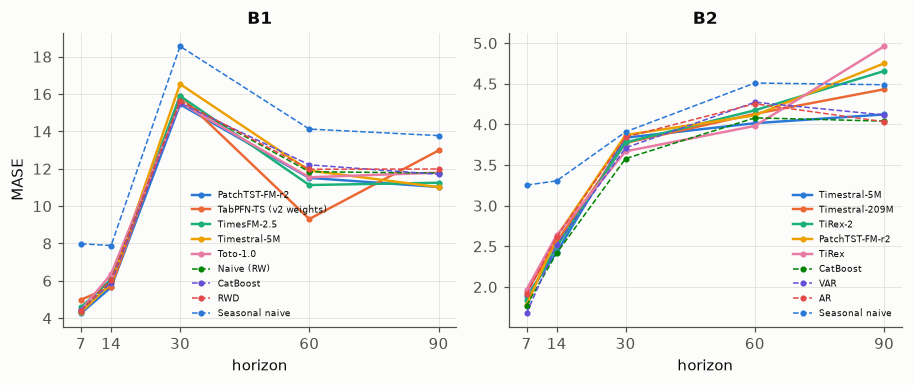

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6), squeeze=False)
for ax, d in zip(axes[0], DATASETS):
    a = agg[agg["dataset"] == d]
    mean = a.groupby("model")["MASE"].mean()
    top = list(mean[mean.index.isin(FMS)].nsmallest(5).index) + list(mean[mean.index.isin(BASE)].nsmallest(3).index)
    for m in dict.fromkeys(top + ["snaive"]):
        g = a[a["model"] == m].groupby("horizon")["MASE"].mean()
        ax.plot(g.index, g.values, marker="o", ms=3, lw=1.6 if m in FMS else 1.0,
                ls="-" if m in FMS else "--", label=NAMES.get(m, m))
    ax.set_title(d)
    ax.set_xlabel("horizon")
    ax.set_xticks(sorted(a["horizon"].unique()))
axes[0][0].set_ylabel("MASE")
for ax in axes[0]:
    ax.legend(fontsize=6, frameon=False)
plt.tight_layout()

### Actual values against the forecasts of the best models

For each dataset, the three best foundation models and the two best baselines on the series in `SERIES` (ranked by
their mean MASE on those series over all horizons and windows), against what actually happened: one row of panels per
series (all five yields on B2), one panel per horizon, recent history in grey, actual values in black, foundation models in solid
and baselines in dashed lines, all from the same test window. Window 1 is the most recent one, ending at the last
observation, so the longer horizons start further back in time. Change `SERIES` or `WINDOW`
(5 rolling windows per horizon)
to look at fewer series or an older window.

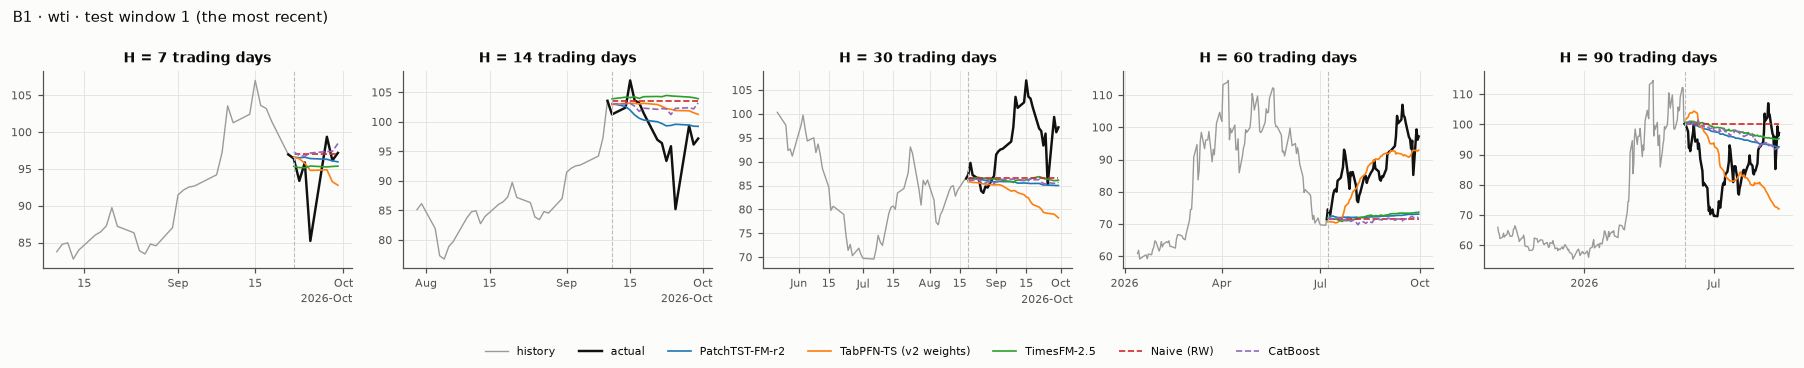

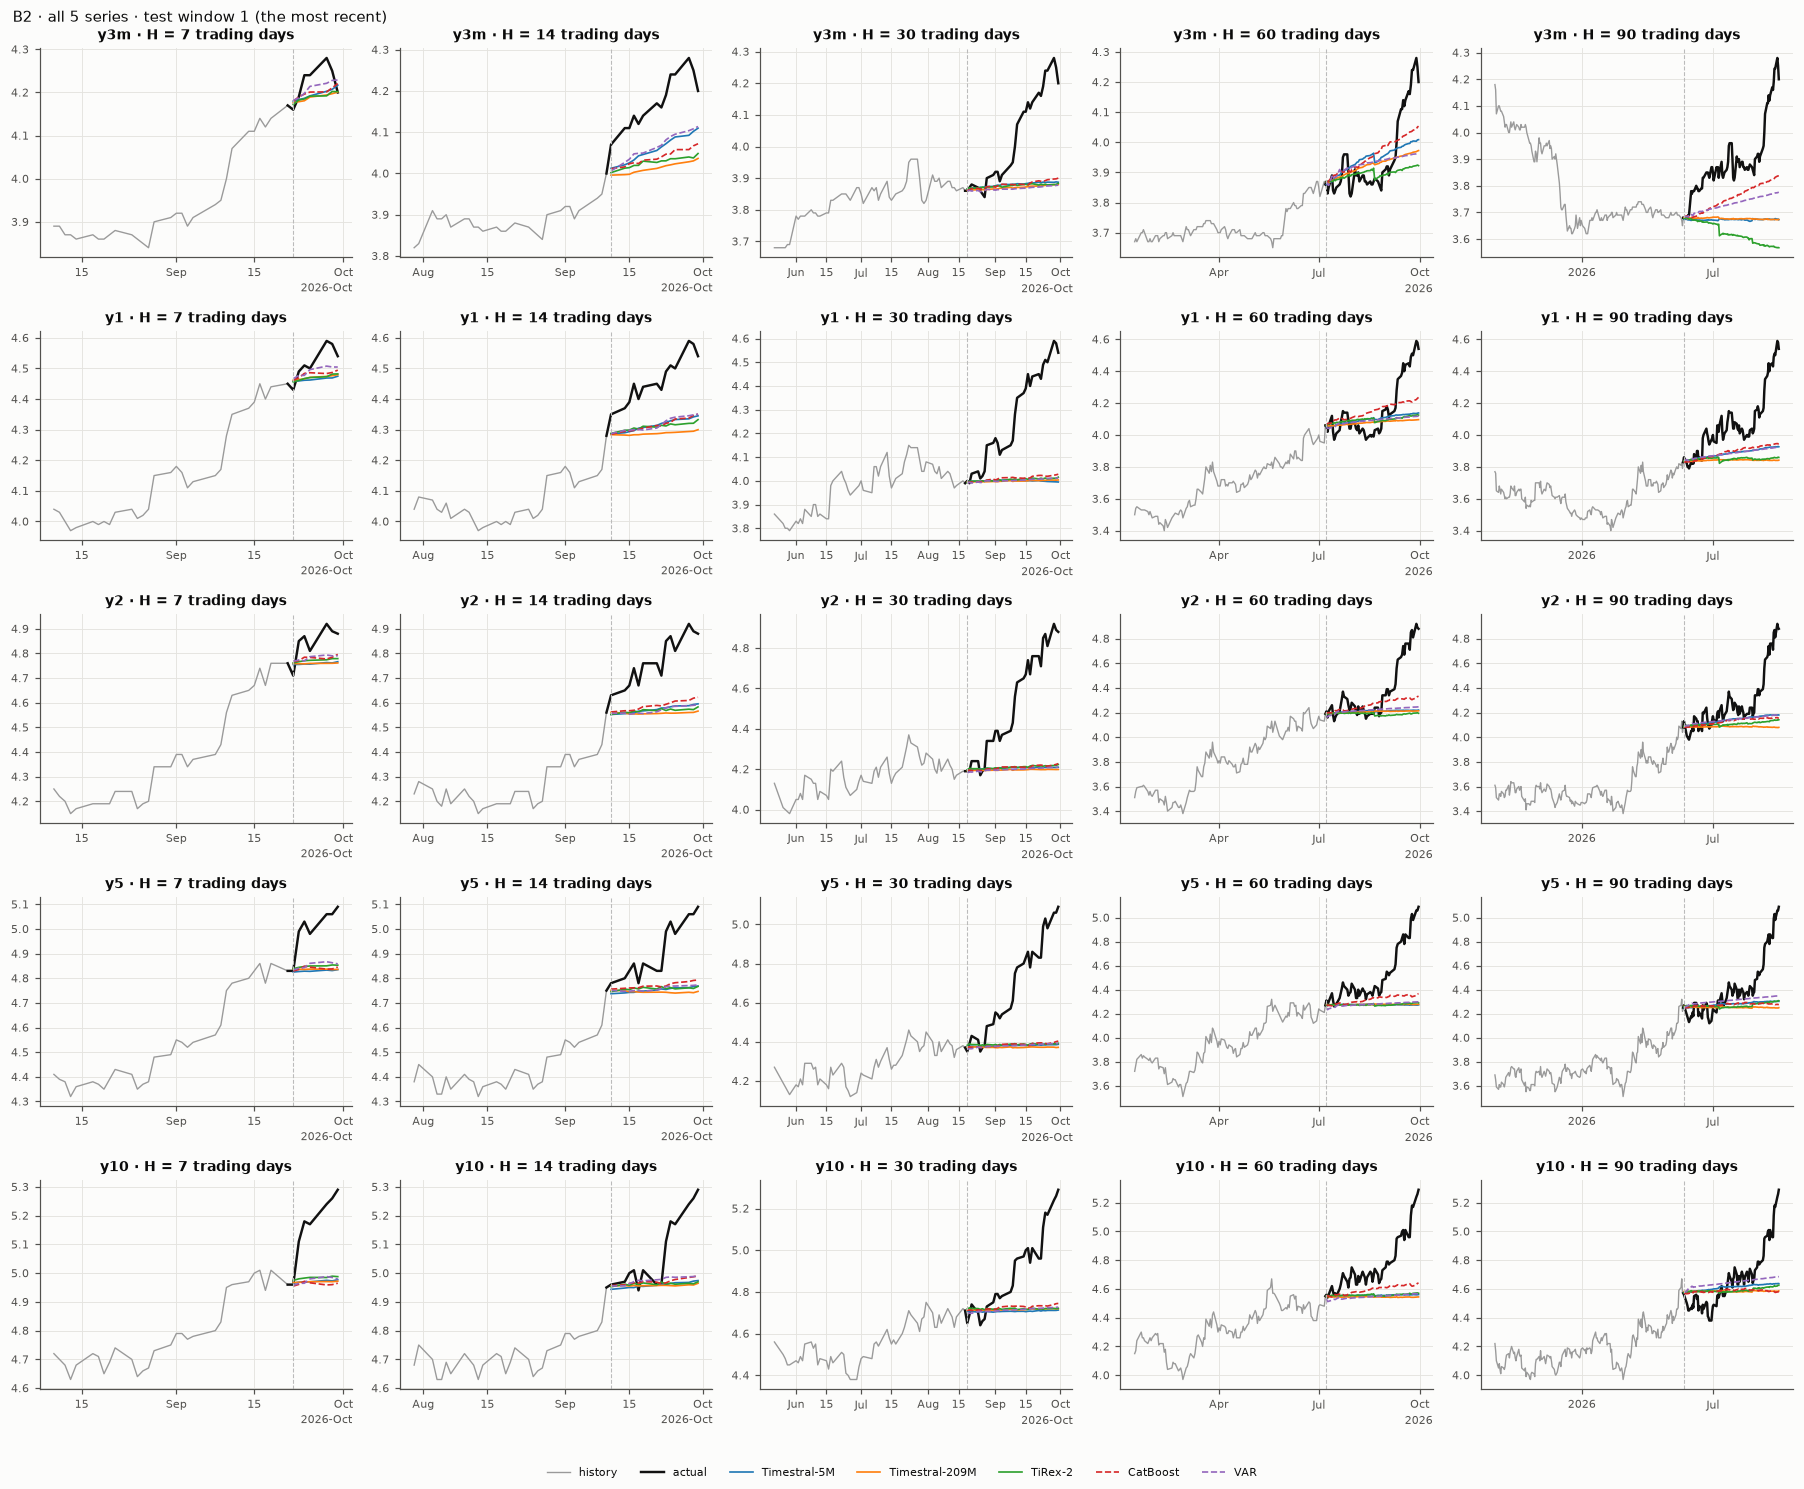

In [11]:
# the series to show: "all", one name or a list of names;
# B2 holds the Treasury yields y3m, y1, y2, y5 and y10
SERIES = {"B1": "wti", "B2": "all"}
WINDOW = 1  # 1 = the most recent test window
pick = {}
for d in DATASETS:
    a = agg[agg["dataset"] == d]
    mean = a[a["series"].isin(series_list(a, d, SERIES[d]))].groupby("model")["MASE"].mean()
    pick[d] = list(mean[mean.index.isin(FMS)].nsmallest(3).index) + list(mean[mean.index.isin(BASE)].nsmallest(2).index)
fc = load_forecasts(ROOT, sorted({m for ms in pick.values() for m in ms}), DATASETS)
for d in DATASETS:
    plot_horizons(fc, load_frame(ROOT, d), d, SERIES[d], pick[d], NAMES, window=WINDOW,
                  colors=model_colors(pick[d]), dashed=BASE)
    plt.show()

#### The forecasts in numbers

For each dataset, the table shows the actual values and the point forecasts of the same five models at one horizon of the same test window, with the naive and seasonal naive rules for reference.
`SERIES` and `WINDOW` work as in the plots above, so there is one table per series; change `HORIZON` to see another
horizon. In each row the forecast closest to the actual value is in bold. The grey rows underneath summarise the
window: the MAE, the RMSE and the mean error ME = mean(actual − forecast), which is positive when the forecasts were
too low. The best value of each is in bold. One window is a small sample, so these numbers can rank the models
differently from the averages over all windows in the tables above. Every horizon of the window is saved as a CSV
file in `results/tables/forecast_vs_actual/`.

In [12]:
HORIZON = {"B1": 14, "B2": 14}   # 7, 14, 30, 60 or 90 trading days
refs = load_forecasts(ROOT, [m for m in ("naive", "snaive") if m not in set(fc["model"])], DATASETS)
both = pd.concat([fc, refs], ignore_index=True) if len(refs) else fc
for d in DATASETS:
    show = pick[d] + [m for m in ("naive", "snaive") if m not in pick[d]]   # naive references, once each
    show_forecast_tables(both, SERIES, HORIZON, show, NAMES, window=WINDOW,
                         datasets=[d], keep=show,
                         save=RESULTS / "tables" / "forecast_vs_actual" / f"B11_{d}.csv")

**B1 · wti · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

,actual,PatchTST-FM-r2,TabPFN-TS (v2 weights),TimesFM-2.5,Naive (RW),CatBoost,Seasonal naive
2026-09-11,101.27,103.10,102.92,103.90,103.57,103.06,92.55
2026-09-14,102.42,102.61,103.15,104.18,103.57,103.05,92.69
2026-09-15,107.02,101.98,103.16,104.12,103.57,103.14,94.21
2026-09-16,103.62,101.17,103.11,104.23,103.57,102.65,97.26
2026-09-17,103.21,100.61,103.05,103.98,103.57,101.78,103.57
2026-09-18,101.44,100.31,103.14,104.27,103.57,102.32,92.55
2026-09-21,96.97,100.03,102.94,104.30,103.57,102.12,92.69
2026-09-22,96.41,99.71,102.63,104.26,103.57,102.26,94.21
2026-09-23,93.38,99.33,102.26,104.48,103.57,102.18,97.26
2026-09-24,95.88,99.40,102.13,104.40,103.57,101.24,103.57


Every horizon of window 1 saved to /home/user/v3/results/tables/forecast_vs_actual/B11_B1.csv


**B2 · y3m · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

,actual,Timestral-5M,Timestral-209M,TiRex-2,CatBoost,VAR,Naive (RW),Seasonal naive
2026-09-11,4.07,4.01,4.00,4.00,4.01,4.01,4.00,3.89
2026-09-14,4.11,4.02,4.00,4.01,4.02,4.03,4.00,3.91
2026-09-15,4.11,4.03,4.00,4.01,4.02,4.03,4.00,3.94
2026-09-16,4.14,4.03,4.00,4.02,4.03,4.05,4.00,3.95
2026-09-17,4.12,4.04,4.01,4.02,4.02,4.05,4.00,4.00
2026-09-18,4.14,4.05,4.01,4.03,4.03,4.05,4.00,3.89
2026-09-21,4.17,4.06,4.01,4.03,4.03,4.06,4.00,3.91
2026-09-22,4.16,4.06,4.02,4.03,4.04,4.07,4.00,3.94
2026-09-23,4.19,4.07,4.02,4.03,4.05,4.08,4.00,3.95
2026-09-24,4.24,4.08,4.02,4.04,4.05,4.09,4.00,4.00


**B2 · y1 · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

... (4 outputs left out)

,actual,Timestral-5M,Timestral-209M,TiRex-2,CatBoost,VAR,Naive (RW),Seasonal naive
2026-09-11,4.78,4.74,4.75,4.75,4.76,4.75,4.75,4.52
2026-09-14,4.80,4.74,4.75,4.76,4.76,4.75,4.75,4.54
2026-09-15,4.83,4.74,4.75,4.75,4.76,4.75,4.75,4.57
2026-09-16,4.86,4.74,4.75,4.76,4.76,4.75,4.75,4.61
2026-09-17,4.78,4.75,4.74,4.76,4.76,4.75,4.75,4.75
2026-09-18,4.86,4.75,4.74,4.76,4.77,4.75,4.75,4.52
2026-09-21,4.83,4.75,4.74,4.76,4.77,4.75,4.75,4.54
2026-09-22,4.83,4.76,4.74,4.77,4.76,4.76,4.75,4.57
2026-09-23,4.99,4.75,4.74,4.76,4.77,4.77,4.75,4.61
2026-09-24,5.03,4.76,4.74,4.76,4.78,4.77,4.75,4.75


**B2 · y10 · H = 14 trading days · test window 1** (2026-09-11 to 2026-09-30)

,actual,Timestral-5M,Timestral-209M,TiRex-2,CatBoost,VAR,Naive (RW),Seasonal naive
2026-09-11,4.96,4.94,4.96,4.95,4.96,4.96,4.95,4.77
2026-09-14,4.97,4.95,4.96,4.96,4.96,4.96,4.95,4.78
2026-09-15,5.00,4.95,4.96,4.96,4.96,4.96,4.95,4.80
2026-09-16,5.01,4.95,4.96,4.96,4.97,4.97,4.95,4.83
2026-09-17,4.94,4.95,4.96,4.96,4.97,4.97,4.95,4.95
2026-09-18,5.01,4.95,4.96,4.97,4.97,4.97,4.95,4.77
2026-09-21,4.96,4.96,4.96,4.96,4.97,4.98,4.95,4.78
2026-09-22,4.96,4.96,4.96,4.97,4.96,4.98,4.95,4.80
2026-09-23,5.11,4.96,4.96,4.96,4.97,4.99,4.95,4.83
2026-09-24,5.18,4.96,4.96,4.96,4.97,4.99,4.95,4.95


Every horizon of window 1 saved to /home/user/v3/results/tables/forecast_vs_actual/B11_B2.csv


## 5 · No single metric gives the full picture

Three checks with the numbers above. First, how similarly do the metrics rank the models? A Spearman correlation of 1
means two metrics order the models identically. Second, which model is best by each metric? Third, the bias of the
five best models of each dataset, which no accuracy metric can show: the mean error ME (positive = the forecast was
too low), the bias ratio ME/MAE (+1 when every error has the same sign and the forecast is always too low, 0 when
errors cancel) and the forecast value added FVA (% better than the naive rule).

In [13]:
rank_metrics = ["MAE", "RMSE", "MASE", "RMSSE", "sMAPE", "MDAPE", "TU1", "MDRAE", "WAPE", "MAAPE"]
for d in DATASETS:
    per_model = agg[agg["dataset"] == d].groupby("model")[rank_metrics].mean()
    corr = per_model.rank().corr(method="spearman")
    print(f"{d}: lowest rank agreement {corr.where(~np.eye(len(corr), dtype=bool)).min().min():.2f}; "
          "best model by metric: " + ", ".join(f"{m} {NAMES.get(per_model[m].idxmin(), per_model[m].idxmin())}"
                                              for m in ["MAE", "RMSE", "MASE", "sMAPE", "MDAPE", "TU1"]))
d0 = DATASETS[0]
corr = agg[agg["dataset"] == d0].groupby("model")[rank_metrics].mean().rank().corr(method="spearman")
corr.round(2).style.background_gradient(cmap="Blues", vmin=0, vmax=1)

B1: lowest rank agreement 0.72; best model by metric: MAE PatchTST-FM-r2, RMSE PatchTST-FM-r2, MASE PatchTST-FM-r2, sMAPE PatchTST-FM-r2, MDAPE PatchTST-FM-r2, TU1 PatchTST-FM-r2
B2: lowest rank agreement 0.94; best model by metric: MAE CatBoost, RMSE CatBoost, MASE CatBoost, sMAPE CatBoost, MDAPE CatBoost, TU1 CatBoost


,MAE,RMSE,MASE,RMSSE,sMAPE,MDAPE,TU1,MDRAE,WAPE,MAAPE
MAE,1.000000,0.980000,1.000000,0.980000,0.980000,0.980000,0.970000,0.770000,0.990000,0.970000
RMSE,0.980000,1.000000,0.980000,1.000000,0.950000,0.950000,0.960000,0.720000,0.980000,0.980000
MASE,1.000000,0.980000,1.000000,0.980000,0.980000,0.980000,0.970000,0.770000,0.990000,0.970000
RMSSE,0.980000,1.000000,0.980000,1.000000,0.950000,0.960000,0.970000,0.730000,0.980000,0.980000
sMAPE,0.980000,0.950000,0.980000,0.950000,1.000000,0.960000,0.980000,0.780000,0.970000,0.940000
MDAPE,0.980000,0.950000,0.980000,0.960000,0.960000,1.000000,0.950000,0.830000,0.970000,0.950000
TU1,0.970000,0.960000,0.970000,0.970000,0.980000,0.950000,1.000000,0.760000,0.970000,0.940000
MDRAE,0.770000,0.720000,0.770000,0.730000,0.780000,0.830000,0.760000,1.000000,0.780000,0.760000
WAPE,0.990000,0.980000,0.990000,0.980000,0.970000,0.970000,0.970000,0.780000,1.000000,0.990000
MAAPE,0.970000,0.980000,0.970000,0.980000,0.940000,0.950000,0.940000,0.760000,0.990000,1.000000


In [14]:
best = (agg.groupby(["dataset", "model"])["MASE"].mean().groupby("dataset", group_keys=False).nsmallest(5))
bias = agg.set_index(["dataset", "model"]).loc[best.index].groupby(["dataset", "model"])[["MASE", "ME", "BIAS", "FVA"]].mean()
bias.rename(index=NAMES, level="model").rename(columns={"BIAS": "ME/MAE"}).round(3)

MASE     ME  ME/MAE     FVA
dataset model                                               
B1      PatchTST-FM-r2          9.580  3.153   0.123   2.901
        TabPFN-TS (v2 weights)  9.774  2.311   0.012 -18.326
        TimesFM-2.5             9.789  2.798   0.037   0.507
        Timestral-5M            9.927  3.487   0.046   0.782
        Toto-1.0                9.934  2.323  -0.033  -3.834
B2      AR                      3.331  0.050   0.308  -4.565
        CatBoost                3.177  0.034   0.211   2.655
        Naive (RW)              3.345  0.052   0.345   0.000
        Timestral-5M            3.257  0.061   0.362  -9.262
        VAR                     3.260  0.029   0.171  -1.133

## 6 · Overall scorecard

Where every model ranks in each (dataset, series, horizon) cell, by MASE and by RMSSE, averaged over the cells. Not
every model runs everywhere (the VAR needs several series, ARIMAX, ARDL and the VARX need covariates), so the ranks of
each cell are rescaled from 0 (best) to 100 (worst) before averaging, and the `cells` column says how many cells a
model was ranked in.
`wins` counts the cells in which the model had the lowest MASE. The scorecard is saved to
`results/tables/table_scorecard_bonus.csv`.

In [15]:
r1 = average_ranks(agg, "MASE", percent=True)
r2 = average_ranks(agg, "RMSSE", percent=True)
wins = agg.loc[agg.groupby(["dataset", "series", "horizon"])["MASE"].idxmin(), "model"].value_counts()
card = pd.DataFrame({"mean rank % (MASE)": r1, "mean rank % (RMSSE)": r2, "wins (MASE)": wins,
                     "cells": agg.groupby("model").size(),
                     "datasets": agg.groupby("model")["dataset"].unique().map(", ".join)}).fillna({"wins (MASE)": 0})
card["family"] = ["foundation model" if m in FMS else BASELINES[m]["family"] for m in card.index]
card = card.sort_values("mean rank % (MASE)")
card.index = card.index.map(lambda m: NAMES.get(m, m))
card.to_csv(RESULTS / "tables" / "table_scorecard_bonus.csv")
card.round(2)

,mean rank % (MASE),mean rank % (RMSSE),wins (MASE),cells,datasets,family
model,,,,,,
CatBoost,15.56,14.32,2.0,30,"B1, B2",machine learning
VAR,22.51,20.00,2.0,25,B2,statistical
Timestral-5M,23.36,21.17,2.0,30,"B1, B2",foundation model
RWD,26.73,27.04,1.0,30,"B1, B2",statistical
PatchTST-FM-r2,27.18,24.23,0.0,30,"B1, B2",foundation model
Naive (RW),30.97,32.81,0.0,30,"B1, B2",statistical
Timestral-209M,31.29,32.53,0.0,30,"B1, B2",foundation model
TiRex-2,31.80,31.69,0.0,30,"B1, B2",foundation model
Kairos (50M),36.13,33.95,1.0,30,"B1, B2",foundation model


## 7 · Key insights


- **Few models beat the random walk on oil and yields.** On B1 five of the 23 foundation models have a lower mean MASE
  than the random walk (PatchTST-FM 9.58, TabPFN-TS 9.77, TimesFM-2.5 9.79, Timestral-5M 9.93, Toto-1.0 9.93, against
  9.94), all by less than 4%, and no baseline does (CatBoost is level, 9.95). On B2 only Timestral-5M among the
  foundation models does (3.26 against 3.35), and three baselines: CatBoost (3.18), the VAR (3.26) and the AR model
  (3.33).
- **CatBoost is the best model on yields by every metric** (mean MASE 3.18) and has the best mean rank over both
  datasets (15.6 on the 0 to 100 scale), ahead of the VAR (22.5, yields only) and Timestral-5M (23.4), the best
  foundation model. The random walk with drift ranks 4th, PatchTST-FM 5th and the random walk 6th.
- **The metrics agree on the winners here.** On B2 the lowest rank correlation between two metrics is 0.94 and every
  metric picks CatBoost; on B1 it is 0.72 (MDRAE ranks the models differently from the rest), but every metric picks
  PatchTST-FM. RMSE and MASE give the same winner on both datasets.
- **A mean can hide a coin flip.** TabPFN-TS beats the random walk on oil by mean MASE (9.77 against 9.94), but its
  mean FVA is -18%: one large win at 60 days (9.31 against 11.84) outweighs losses at three of the other four
  horizons.
- **Short horizons favour the trees and the VAR.** At 7 days on yields LightGBM (1.66), XGBoost (1.67) and the VAR
  (1.68) beat the best foundation model (PatchTST-FM, 1.78) and the random walk (1.98); from 30 days on LightGBM and
  XGBoost are 5% to 15% behind the random walk.

## References

- Definitions of the fourteen metrics and how to choose among them (Section 1): Manokhin, V. (2026). *Mastering Modern Time Series Forecasting: A Comprehensive Guide to Statistical, Machine Learning, and Deep Learning Models in Python*. North Star Academic Press, ISBN 978-1-9194658-3-8, Chapter 3 (metric definitions, Sections 3.1 to 3.11). [Book page](https://leanpub.com/mastering_modern_time_series_forecasting)
- The six-metric table layout of Section 3, from an earlier study by the authors of this book: Sengupta, S., Chakraborty, T., & Singh, S. K. (2025). Forecasting CPI inflation under economic policy and geopolitical uncertainties. *International Journal of Forecasting*, 41(3), 953-981 (Section 5.2, table layout). [doi:10.1016/j.ijforecast.2024.08.005](https://doi.org/10.1016/j.ijforecast.2024.08.005)
- Squared error rewards the mean, absolute error the median (Section 1): Gneiting, T. (2011). Making and evaluating point forecasts. *Journal of the American Statistical Association*, 106(494), 746-762. [doi:10.1198/jasa.2011.r10138](https://doi.org/10.1198/jasa.2011.r10138)
- Relative errors and the MDRAE (Section 1): Armstrong, J. S., & Collopy, F. (1992). Error measures for generalizing about forecasting methods: empirical comparisons. *International Journal of Forecasting*, 8(1), 69-80. [doi:10.1016/0169-2070(92)90008-W](https://doi.org/10.1016/0169-2070%2892%2990008-W)
- Scaled errors and the MASE (Section 1): Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679-688. [doi:10.1016/j.ijforecast.2006.03.001](https://doi.org/10.1016/j.ijforecast.2006.03.001)
- The asymmetry of the sMAPE (Section 1): Goodwin, P., & Lawton, R. (1999). On the asymmetry of the symmetric MAPE. *International Journal of Forecasting*, 15(4), 405-408. [doi:10.1016/S0169-2070(99)00007-2](https://doi.org/10.1016/S0169-2070%2899%2900007-2)
- MAAPE (Section 1): Kim, S., & Kim, H. (2016). A new metric of absolute percentage error for intermittent demand forecasts. *International Journal of Forecasting*, 32(3), 669-679 (MAAPE). [doi:10.1016/j.ijforecast.2015.12.003](https://doi.org/10.1016/j.ijforecast.2015.12.003)
- Theil's U1 (Section 1): Theil, H. (1966). *Applied Economic Forecasting*. North-Holland, Amsterdam (U1). No DOI: the book predates them.
- Forecast value added (Section 1): Gilliland, M. (2013). FVA: a reality check on forecasting practices. *Foresight*, 29, 14-18. [RePEc record](https://econpapers.repec.org/RePEc:for:ijafaa:y:2013:i:29:p:14-18)
- The RMSSE of the M5 competition (Section 1): Makridakis, S., Spiliotis, E., & Assimakopoulos, V. (2022). M5 accuracy competition: results, findings, and conclusions. *International Journal of Forecasting*, 38(4), 1346-1364 (RMSSE). [doi:10.1016/j.ijforecast.2021.11.013](https://doi.org/10.1016/j.ijforecast.2021.11.013)